In [13]:
import pandas as pd
import numpy as np
from Bio.Data import CodonTable
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqUtils import seq3
import random
from Bio.SeqUtils import GC123
import multiprocessing as mp

In [14]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['svg.fonttype']='none'

## Compare codon use using Measure Independent of Length and Composition (MILC)

In [15]:
import pandas as pd
from Bio.Data import CodonTable

# Get the standard genetic code table
standard_table = CodonTable.unambiguous_dna_by_name["Standard"]


def get_amino_acid_codon_dict():
    # Initialize the standard codon table
    codon_table = CodonTable.unambiguous_dna_by_name["Standard"]

    # Initialize the dictionary to store amino acids and their codons
    amino_acid_codons = {}

    # Iterate through the codons and map them to their corresponding amino acids
    for codon, amino_acid in codon_table.forward_table.items():
        amino_acid_codons.setdefault(amino_acid, []).append(codon)

    return amino_acid_codons
amino_acid_codon_dict = get_amino_acid_codon_dict()

def get_codon_counts(gene_name, name=True):
    if name:
        gene_sequence=str(my_dict[gene_name].seq)
    else:
        gene_sequence=gene_name
 
    codon_table = {
        'TTT': 0, 'TTC': 0, 'TTA': 0, 'TTG': 0, 'CTT': 0, 'CTC': 0, 'CTA': 0, 'CTG': 0,
        'ATT': 0, 'ATC': 0, 'ATA': 0, 'ATG': 0, 'GTT': 0, 'GTC': 0, 'GTA': 0, 'GTG': 0,
        'TAT': 0, 'TAC': 0,  'CAT': 0, 'CAC': 0, 'CAA': 0, 'CAG': 0,
        'AAT': 0, 'AAC': 0, 'AAA': 0, 'AAG': 0, 'GAT': 0, 'GAC': 0, 'GAA': 0, 'GAG': 0,
        'TCT': 0, 'TCC': 0, 'TCA': 0, 'TCG': 0, 'CCT': 0, 'CCC': 0, 'CCA': 0, 'CCG': 0,
        'ACT': 0, 'ACC': 0, 'ACA': 0, 'ACG': 0, 'GCT': 0, 'GCC': 0, 'GCA': 0, 'GCG': 0,
        'TGT': 0, 'TGC': 0, 'TGG': 0, 'CGT': 0, 'CGC': 0, 'CGA': 0, 'CGG': 0,
        'AGT': 0, 'AGC': 0, 'AGA': 0, 'AGG': 0, 'GGT': 0, 'GGC': 0, 'GGA': 0, 'GGG': 0,
    }

    gene_sequence = gene_sequence.upper().replace(" ", "")
    seq_length = len(gene_sequence)


    for i in range(0, seq_length, 3):
        codon = gene_sequence[i:i+3]
        if codon in codon_table:
            codon_table[codon] += 1

    codon_counts_df = pd.DataFrame.from_dict(codon_table, orient='index', columns=['Codon Count'])
 
    if len(gene_sequence)%3!=0:
        return codon_counts_df.fillna(pd.NA)
    return codon_counts_df
def get_fdict(series):
    aa_fdict={}
    for aa in amino_acid_codon_dict:
        cs=series.loc[amino_acid_codon_dict[aa]]
        fs=cs/cs.sum()
        for index,values in fs.items():
            aa_fdict[index]=values
    
    return pd.DataFrame.from_dict(aa_fdict,orient="index").sort_index()
def get_C(series):
    C=0
    for aa in amino_acid_codon_dict:
        cs=series.loc[amino_acid_codon_dict[aa]]
        if cs.sum()>0:
            C+=len(amino_acid_codon_dict[aa])-1

    C=C/np.sum(series)-.5
            
    
    
    return C
def get_MILC(gene):
    o=dfr.loc[gene,:]
    ofreqs=get_fdict(o)

    dfri=pd.concat([efreqs,ofreqs,o],axis=1)
    dfri.columns=["Ef","Of","O"]
    dfri=dfri[dfri.Of!=0]

    MILC=2*np.sum(dfri.O*(np.log(dfri.Of)-np.log(dfri.Ef)))/np.sum(o)-get_C(o)
    return MILC

In [9]:
%%bash
wget https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/014/529/535/GCF_014529535.2_BU_Bcop_v2.1/GCF_014529535.2_BU_Bcop_v2.1_cds_from_genomic.fna.gz
gunzip GCF_014529535.2_BU_Bcop_v2.1_cds_from_genomic.fna.gz
mv GCF_014529535.2_BU_Bcop_v2.1_cds_from_genomic.fna ncbi_dataset/data/GCF_014529535.2/GCF_014529535.2_BU_Bcop_v2.1_cds_from_genomic.fna

--2026-06-28 14:11:31--  https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/014/529/535/GCF_014529535.2_BU_Bcop_v2.1/GCF_014529535.2_BU_Bcop_v2.1_cds_from_genomic.fna.gz
Resolving ftp.ncbi.nlm.nih.gov... 130.14.250.11, 130.14.250.12, 2607:f220:41e:250::13, ...
Connecting to ftp.ncbi.nlm.nih.gov|130.14.250.11|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 11486904 (11M) [application/x-gzip]
Saving to: ‘GCF_014529535.2_BU_Bcop_v2.1_cds_from_genomic.fna.gz’

     0K .......... .......... .......... .......... ..........  0% 2.16M 5s
    50K .......... .......... .......... .......... ..........  0% 3.68M 4s
   100K .......... .......... .......... .......... ..........  1%  109M 3s
   150K .......... .......... .......... .......... ..........  1% 3.88M 3s
   200K .......... .......... .......... .......... ..........  2% 59.1M 2s
   250K .......... .......... .......... .......... ..........  2%  126M 2s
   300K .......... .......... .......... .......... .......... 

In [16]:
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col='accession')
dfriso=dfriso[(dfriso.type=='dipt')|(dfriso.tree_HTG==True)]
input_file = open(f"ncbi_dataset/data/GCF_014529535.2/GCF_014529535.2_BU_Bcop_v2.1_cds_from_genomic.fna")
fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
fasta={"_".join(x.split("cds_")[1].split("_")[0:2]):fasta[x] for x in fasta}
fasta={x:fasta[x] for x in fasta if x in list(dfriso.index)}

In [17]:
my_dict=fasta
with mp.Pool(29) as p:
    results = p.map(get_codon_counts, fasta.keys())
#compute expected frequency counts of codons (pooling across all protein coding genes)
dfr=pd.concat(results,axis=1)
dfr.columns=fasta.keys()
dfr=dfr.T
dfrTot=dfr.loc[dfriso[dfriso.type=='dipt'].index,:].sum(axis=0)
dfr_bradysia=dfr.copy()
efreqs=get_fdict(dfrTot)

In [18]:
#compute the MILC statistic across all protein-coding genes
td=list(fasta.keys())
with mp.Pool(29) as p:
    MILC = p.map(get_MILC, td)

In [19]:
dfriso.loc[td,'MILC']=MILC

In [20]:
dfrisoi=dfriso.copy()
dfrisoi['tree_HTG']=dfrisoi['tree_HTG'].replace(False,'Dipteran')
dfrisoi['tree_HTG']=dfrisoi['tree_HTG'].replace(True,'HGT')

In [19]:
%%bash
curl -OJX GET "https://api.ncbi.nlm.nih.gov/datasets/v2alpha/genome/accession/GCF_002217175.1/download?include_annotation_type=GENOME_GFF&include_annotation_type=PROT_FASTA&include_annotation_type=CDS_FASTA&hydrated=FULLY_HYDRATED"

unzip -o ncbi_dataset.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0Warning: Failed to create the file ncbi_dataset.zip: File exists
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
curl: (23) Failed writing header


Archive:  ncbi_dataset.zip
  inflating: README.md               
  inflating: ncbi_dataset/data/assembly_data_report.jsonl  
  inflating: ncbi_dataset/data/GCF_002217175.1/cds_from_genomic.fna  
  inflating: ncbi_dataset/data/GCF_002217175.1/genomic.gff  
  inflating: ncbi_dataset/data/GCF_002217175.1/protein.faa  
  inflating: ncbi_dataset/data/dataset_catalog.json  
  inflating: md5sum.txt              


In [21]:
from Bio import SeqIO
from collections import defaultdict
def longest_iso(ac):
    gff=pd.read_csv(f"ncbi_dataset/data/{ac}/genomic.gff",sep="\t",comment="#",header=None)
    def get_gene(x):
        return gff[gff[8].str.contains(x)].iloc[0,8].split(";gene=")[1].split(";")[0]
        
    input_file = open(f"ncbi_dataset/data/{ac}/protein.faa") 
    fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
    
    cds=gff[gff[2]=='CDS'].copy()
    cds['prot']=[x.split(";")[0].split("-")[1] for x in cds[8]]
    cds['gene']=[x.split(";gene=")[1].split(";")[0] for x in cds[8]]

    cds_gene={}
    gene_cds=defaultdict(set)
    for index, row in cds.iterrows():
        cds_gene[row.prot]=row.gene
        gene_cds[row.gene].add(row.prot)

    cds_len={x:len(str(fasta[x].seq)) for x in fasta}
    longest = []

    for gene, proteins in gene_cds.items():
        max_len=max([cds_len[x] for x in proteins])
        longest.append([x for x in proteins if cds_len[x]==max_len][0])
    longest_records = []

    for x in longest:
        record = fasta[x]
        record.id = x

        longest_records.append(record)

    
    SeqIO.write(
        longest_records,
        f"ncbi_dataset/data/{ac}/longest_isoform.fasta",
        "fasta"
    )
longest_iso("GCF_002217175.1")

In [22]:
##compute folsomia MILC values with same expectation
input_file = open(f"ncbi_dataset/data/GCF_002217175.1/longest_isoform.fasta")
prot = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
input_file = open(f"ncbi_dataset/data/GCF_002217175.1/cds_from_genomic.fna")
fasta_folsomia = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
fasta_folsomia={"_".join(x.split("cds_")[1].split("_")[0:2]):fasta_folsomia[x] for x in fasta_folsomia}
fasta_folsomia={x:fasta_folsomia[x] for x in fasta_folsomia if x in list(prot.keys())}
my_dict=fasta_folsomia
with mp.Pool(29) as p:
    results = p.map(get_codon_counts, my_dict.keys())
#compute expected frequency counts of codons (pooling across all protein coding genes)
dfr_folsomia=pd.concat(results,axis=1)
dfr_folsomia.columns=fasta_folsomia.keys()
dfr=dfr_folsomia.T
my_dict=fasta_folsomia
td=list(fasta_folsomia.keys())
with mp.Pool(29) as p:
    MILC_folsomia = p.map(get_MILC, td)

In [23]:
folsomia_df=pd.DataFrame(index=td,columns=['MILC','tree_HTG'])
folsomia_df['MILC']=MILC_folsomia
folsomia_df['tree_HTG']='Folsomia_candida'

In [24]:
MILC_df=pd.concat([dfrisoi.loc[:,['tree_HTG','MILC']],folsomia_df])

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


(0.0, 1.25)

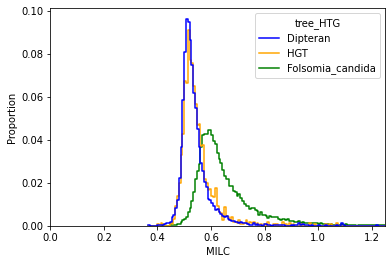

In [25]:
import seaborn as sns
sns.histplot(
    data=MILC_df[MILC_df.tree_HTG.isin(['Dipteran','HGT','Folsomia_candida'])],
    x='MILC',
    hue='tree_HTG',
    palette={'HGT': 'orange', 'Dipteran': 'blue','Folsomia_candida':'green'},
    stat='proportion',
    element='step',
    fill=False,
    common_norm=False 
)
plt.xlim(0,1.25)


In [26]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import warnings

# Suppress all warnings
warnings.filterwarnings("ignore")
##written by RK and chatgpt
scaler = StandardScaler()
dfr_freq = dfr_bradysia.div(dfr_bradysia.sum(axis=1), axis=0)
scaled_data = scaler.fit_transform(dfr_freq)

# Step 2: Perform PCA
pca = PCA()
pca_result = pca.fit_transform(scaled_data)

# Step 3: Get explained variance
explained_variance = pca.explained_variance_ratio_




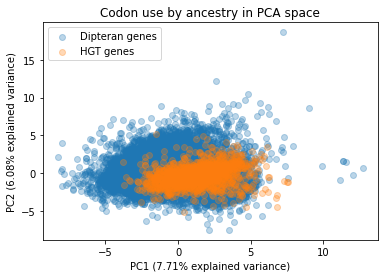

In [27]:

# Step 4: Plot the first two principal components

df1=pd.DataFrame(pca_result[:,0],index=dfr_bradysia.index)
df2=pd.DataFrame(pca_result[:,1],index=dfr_bradysia.index)

plt.scatter(df1.loc[(MILC_df[MILC_df.tree_HTG=='Dipteran'].index),:], # position on the first principal component of the observations
            df2.loc[(MILC_df[MILC_df.tree_HTG=='Dipteran'].index),:], alpha=0.30,label='Dipteran genes') # position on the second principal component of the observations
plt.scatter(df1.loc[(MILC_df[MILC_df.tree_HTG=='HGT'].index),:], # position on the first principal component of the observations
            df2.loc[(MILC_df[MILC_df.tree_HTG=='HGT'].index),:], alpha=0.30,label='HGT genes') # position on the second principal component of the observations

plt.title('Codon use by ancestry in PCA space')
plt.xlabel(f'PC1 ({explained_variance[0]:.2%} explained variance)')
plt.ylabel(f'PC2 ({explained_variance[1]:.2%} explained variance)')
plt.legend()

## GC content analysis

In [28]:
input_file = open(f"ncbi_dataset/data/GCF_002217175.1/longest_isoform.fasta")
prot = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
input_file = open(f"ncbi_dataset/data/GCF_002217175.1/cds_from_genomic.fna")
fasta_folsomia = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
fasta_folsomia={"_".join(x.split("cds_")[1].split("_")[0:2]):fasta_folsomia[x] for x in fasta_folsomia}
fasta_folsomia={x:fasta_folsomia[x] for x in fasta_folsomia if x in list(prot.keys())}

input_file = open(f"ncbi_dataset/data/GCF_014529535.2/GCF_014529535.2_BU_Bcop_v2.1_cds_from_genomic.fna")
fasta_bradysia = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
fasta_bradysia={"_".join(x.split("cds_")[1].split("_")[0:2]):fasta_bradysia[x] for x in fasta_bradysia}
fasta_bradysia={x:fasta_bradysia[x] for x in fasta_bradysia if x in list(dfriso.index)}

In [29]:
fasta=fasta_bradysia|fasta_folsomia

In [30]:
def get_GC(gene):
    g=GC123(fasta[gene].seq)
    return g[0],g[-1]
with mp.Pool(29) as p:
    results = p.map(get_GC, MILC_df.index)
MILC_df.loc[MILC_df.index,["GC","GC3"]]=results


In [31]:
import seaborn as sns
sns.set_palette("tab10")

In [32]:
import seaborn as sns

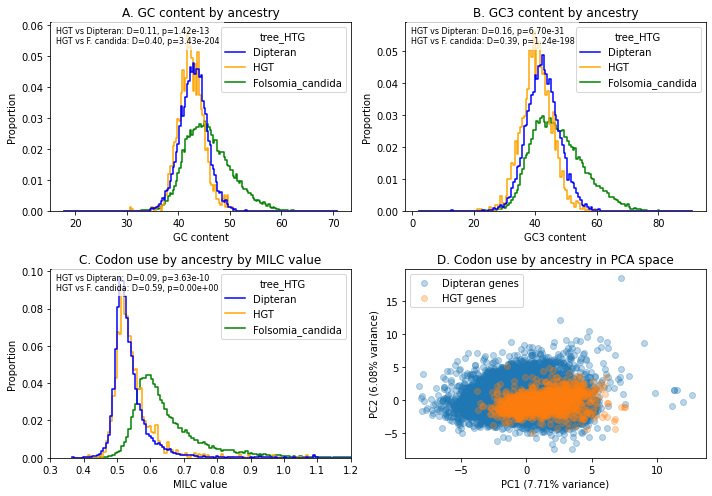

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

palette = {
    'HGT': 'orange',
    'Dipteran': 'blue',
    'Folsomia_candida': 'green'
}

def add_ks_stats(ax, df, variable, groups=('HGT', 'Dipteran', 'Folsomia_candida')):
    """Add pairwise KS distance and p-value text to an axis."""
    
    comparisons = [
        ('HGT', 'Dipteran'),
        ('HGT', 'Folsomia_candida')
    ]
    
    lines = []
    for g1, g2 in comparisons:
        x1 = df.loc[df['tree_HTG'] == g1, variable].dropna()
        x2 = df.loc[df['tree_HTG'] == g2, variable].dropna()
        
        ks_stat, pval = ks_2samp(x1, x2)
        
        g1_label = g1.replace('Folsomia_candida', 'F. candida')
        g2_label = g2.replace('Folsomia_candida', 'F. candida')
        
        lines.append(f'{g1_label} vs {g2_label}: D={ks_stat:.2f}, p={pval:.2e}')
    
    ax.text(
        0.02, 0.98,
        '\n'.join(lines),
        transform=ax.transAxes,
        va='top',
        ha='left',
        fontsize=8,
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.75)
    )


f, ax = plt.subplots(2, 2, figsize=(10, 7))

sns.histplot(
    data=MILC_df,
    ax=ax[0, 0],
    x='GC',
    hue='tree_HTG',
    palette=palette,
    stat='proportion',
    element='step',
    fill=False,
    common_norm=False
)
ax[0, 0].set_title('A. GC content by ancestry')
ax[0, 0].set_xlabel('GC content')
add_ks_stats(ax[0, 0], MILC_df, 'GC')


sns.histplot(
    data=MILC_df,
    ax=ax[0, 1],
    x='GC3',
    hue='tree_HTG',
    palette=palette,
    stat='proportion',
    element='step',
    fill=False,
    common_norm=False
)
ax[0, 1].set_title('B. GC3 content by ancestry')
ax[0, 1].set_xlabel('GC3 content')
add_ks_stats(ax[0, 1], MILC_df, 'GC3')


sns.histplot(
    data=MILC_df,
    ax=ax[1, 0],
    x='MILC',
    hue='tree_HTG',
    palette=palette,
    stat='proportion',
    element='step',
    fill=False,
    common_norm=False
)
ax[1, 0].set_xlim(.3, 1.2)
ax[1, 0].set_title('C. Codon use by ancestry by MILC value')
ax[1, 0].set_xlabel('MILC value')
add_ks_stats(ax[1, 0], MILC_df, 'MILC')


ax[1, 1].scatter(
    df1.loc[MILC_df[MILC_df.tree_HTG == 'Dipteran'].index, :],
    df2.loc[MILC_df[MILC_df.tree_HTG == 'Dipteran'].index, :],
    alpha=0.30,
    
    label='Dipteran genes'
)

ax[1, 1].scatter(
    df1.loc[MILC_df[MILC_df.tree_HTG == 'HGT'].index, :],
    df2.loc[MILC_df[MILC_df.tree_HTG == 'HGT'].index, :],
    alpha=0.30,
    label='HGT genes'
)

ax[1, 1].set_title('D. Codon use by ancestry in PCA space')
ax[1, 1].set_xlabel(f'PC1 ({explained_variance[0]:.2%} variance)')
ax[1, 1].set_ylabel(f'PC2 ({explained_variance[1]:.2%} variance)')
ax[1, 1].legend()

plt.tight_layout()
plt.savefig(
    'figures/GC_codon_combined_histograms.svg',
    format='svg',
    bbox_inches='tight'
)
plt.show()

In [35]:
MILC_df.to_csv("outputs/nucleotide_composition_stats.csv")